In [1]:

# Importing required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import glob

# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Machine Learning Algorithm
from sklearn.ensemble import GradientBoostingClassifier

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

# Display settings
pd.set_option('display.max_columns', None)
sns.set_style("whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:

# Download the Kaggle dataset

!pip install -q kagglehub

import kagglehub
import os

# Download dataset
path = kagglehub.dataset_download(
    "jessemostipak/hotel-booking-demand"
)

# Locate the CSV file
csv_files = []

for root, dirs, files in os.walk(path):
    for file in files:
        if file.endswith(".csv"):
            csv_files.append(os.path.join(root, file))

print("Dataset downloaded successfully!")
print("Available CSV files:", csv_files)

# Load the hotel booking dataset
df = pd.read_csv(csv_files[0])

print("\nDataset loaded successfully!")
print("Dataset Shape:", df.shape)

# Display first five records
df.head()

Using Colab cache for faster access to the 'hotel-booking-demand' dataset.
Dataset downloaded successfully!
Available CSV files: ['/kaggle/input/hotel-booking-demand/hotel_bookings.csv']

Dataset loaded successfully!
Dataset Shape: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [3]:

# STEP 1: DATA PREPROCESSING

# 1. Display dataset dimensions
print("Dataset Shape:", df.shape)

# 2. Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# 3. Dataset information
print("\nDataset Information:")
df.info()

# 4. Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 5. Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# 6. Statistical summary
print("\nStatistical Summary:")
display(df.describe(include="all").T)

Dataset Shape: (119390, 32)

Column Names:
['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled   

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
hotel,119390,2,City Hotel,79330,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_canceled,119390.0,NaN,NaN,NaN,0.370416,0.482918,0.0,0.0,0.0,1.0,1.0
lead_time,119390.0,NaN,NaN,NaN,104.011416,106.863097,0.0,18.0,69.0,160.0,737.0
arrival_date_year,119390.0,NaN,NaN,NaN,2016.156554,0.707476,2015.0,2016.0,2016.0,2017.0,2017.0
arrival_date_month,119390,12,August,13877,NaN,NaN,NaN,NaN,NaN,NaN,NaN
arrival_date_week_number,119390.0,NaN,NaN,NaN,27.165173,13.605138,1.0,16.0,28.0,38.0,53.0
arrival_date_day_of_month,119390.0,NaN,NaN,NaN,15.798241,8.780829,1.0,8.0,16.0,23.0,31.0
stays_in_weekend_nights,119390.0,NaN,NaN,NaN,0.927599,0.998613,0.0,0.0,1.0,2.0,19.0
stays_in_week_nights,119390.0,NaN,NaN,NaN,2.500302,1.908286,0.0,1.0,2.0,3.0,50.0
adults,119390.0,NaN,NaN,NaN,1.856403,0.579261,0.0,2.0,2.0,2.0,55.0


In [4]:
# STEP 2: DATA CLEANING

# Create a copy of the dataset
df = df.copy()

# Remove duplicate records
df = df.drop_duplicates()

# Drop columns with excessive missing values
# and identifier-like information
df.drop(columns=["company", "agent"], inplace=True, errors="ignore")

# Remove columns that cause target leakage
df.drop(
    columns=["reservation_status", "reservation_status_date"],
    inplace=True,
    errors="ignore"
)

# Handle missing values in children column
df["children"] = df["children"].fillna(df["children"].median())

# Handle missing values in country column
df["country"] = df["country"].fillna("Unknown")

# Remove rows with missing target values
df.dropna(subset=["is_canceled"], inplace=True)

# Display updated dataset information
print("Data cleaning completed!")

print("\nUpdated Dataset Shape:", df.shape)

print("\nRemaining Missing Values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nRemaining Duplicate Records:", df.duplicated().sum())

Data cleaning completed!

Updated Dataset Shape: (87396, 28)

Remaining Missing Values:
Series([], dtype: int64)

Remaining Duplicate Records: 286


In [6]:
# Remove duplicates created or revealed after missing-value handling
df = df.drop_duplicates()

print("Final Dataset Shape:", df.shape)

print("\nRemaining Missing Values:", df.isnull().sum().sum())

print("Remaining Duplicate Records:", df.duplicated().sum())

Final Dataset Shape: (87110, 28)

Remaining Missing Values: 0
Remaining Duplicate Records: 0


In [7]:
# STEP 3: EXPLORATORY DATA ANALYSIS

# Booking cancellation distribution
print("Cancellation Distribution:")
print(df["is_canceled"].value_counts())

# Cancellation percentage
print("\nCancellation Percentage:")
print(df["is_canceled"].value_counts(normalize=True) * 100)

# Hotel type distribution
print("\nHotel Type Distribution:")
print(df["hotel"].value_counts())

# Average lead time by cancellation status
print("\nAverage Lead Time:")
print(df.groupby("is_canceled")["lead_time"].mean())

Cancellation Distribution:
is_canceled
0    63349
1    23761
Name: count, dtype: int64

Cancellation Percentage:
is_canceled
0    72.722994
1    27.277006
Name: proportion, dtype: float64

Hotel Type Distribution:
hotel
City Hotel      53238
Resort Hotel    33872
Name: count, dtype: int64

Average Lead Time:
is_canceled
0     70.110073
1    105.368671
Name: lead_time, dtype: float64


In [8]:
# STEP 4: FEATURE SELECTION

# Separate independent and dependent variables
X = df.drop(columns=["is_canceled"])
y = df["is_canceled"]

# Identify numerical features
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Identify categorical features
categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nTotal Features:", X.shape[1])

Numerical Features:
['lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']

Categorical Features:
['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type']

Total Features: 27


In [9]:
# STEP 5: DATA TRANSFORMATION

from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False,
        dtype=np.float32
    ))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [10]:
# STEP 6: TRAIN-TEST SPLITTING

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dataset split completed!")

print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Dataset split completed!

Training Data: (69688, 27)
Testing Data: (17422, 27)

Training Target: (69688,)
Testing Target: (17422,)


In [11]:
# STEP 7: APPLY DATA TRANSFORMATION

# Fit the preprocessing pipeline on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data
X_test_processed = preprocessor.transform(X_test)

print("Data transformation completed!")

print("\nProcessed Training Shape:", X_train_processed.shape)
print("Processed Testing Shape:", X_test_processed.shape)

Data transformation completed!

Processed Training Shape: (69688, 248)
Processed Testing Shape: (17422, 248)


In [12]:
# STEP 8: MODEL TRAINING

from sklearn.ensemble import GradientBoostingClassifier

# Create Gradient Boosting model
model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# Train the model
model.fit(X_train_processed, y_train)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


In [13]:
# STEP 9: MODEL PREDICTION

# Predict booking cancellation
y_pred = model.predict(X_test_processed)

# Predict cancellation probabilities
y_probability = model.predict_proba(X_test_processed)[:, 1]

print("Predictions generated successfully!")

print("\nActual Values:")
print(y_test.iloc[:10].values)

print("\nPredicted Values:")
print(y_pred[:10])

Predictions generated successfully!

Actual Values:
[0 1 0 1 0 0 0 0 0 0]

Predicted Values:
[0 0 0 1 0 0 0 0 0 0]


In [14]:
# STEP 10: MODEL EVALUATION

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_probability)

print("MODEL PERFORMANCE")
print("------------------------------")

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

MODEL PERFORMANCE
------------------------------
Accuracy  : 0.8209
Precision : 0.7327
Recall    : 0.5404
F1 Score  : 0.6220
ROC-AUC   : 0.8779

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.93      0.88     12670
           1       0.73      0.54      0.62      4752

    accuracy                           0.82     17422
   macro avg       0.79      0.73      0.75     17422
weighted avg       0.81      0.82      0.81     17422



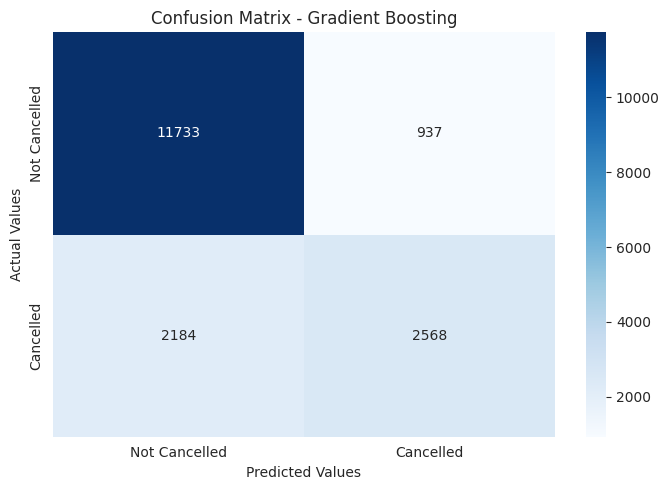

In [15]:
# STEP 11: CONFUSION MATRIX

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Cancelled", "Cancelled"],
    yticklabels=["Not Cancelled", "Cancelled"]
)

plt.title("Confusion Matrix - Gradient Boosting")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.tight_layout()
plt.show()

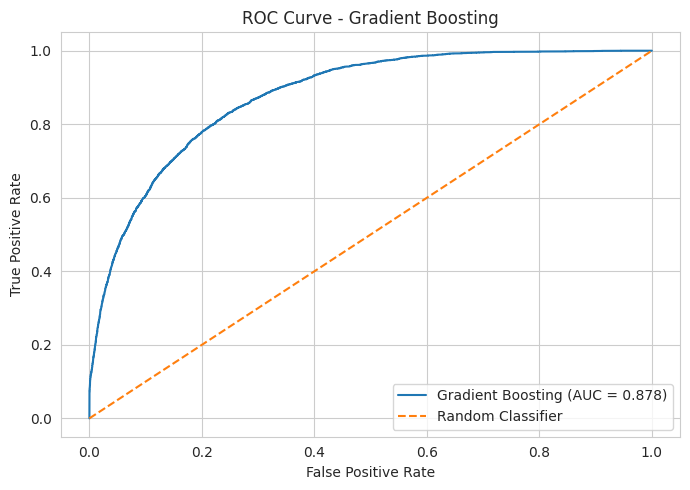

In [16]:
# STEP 12: ROC CURVE

from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_test, y_probability)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Gradient Boosting (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curve - Gradient Boosting")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

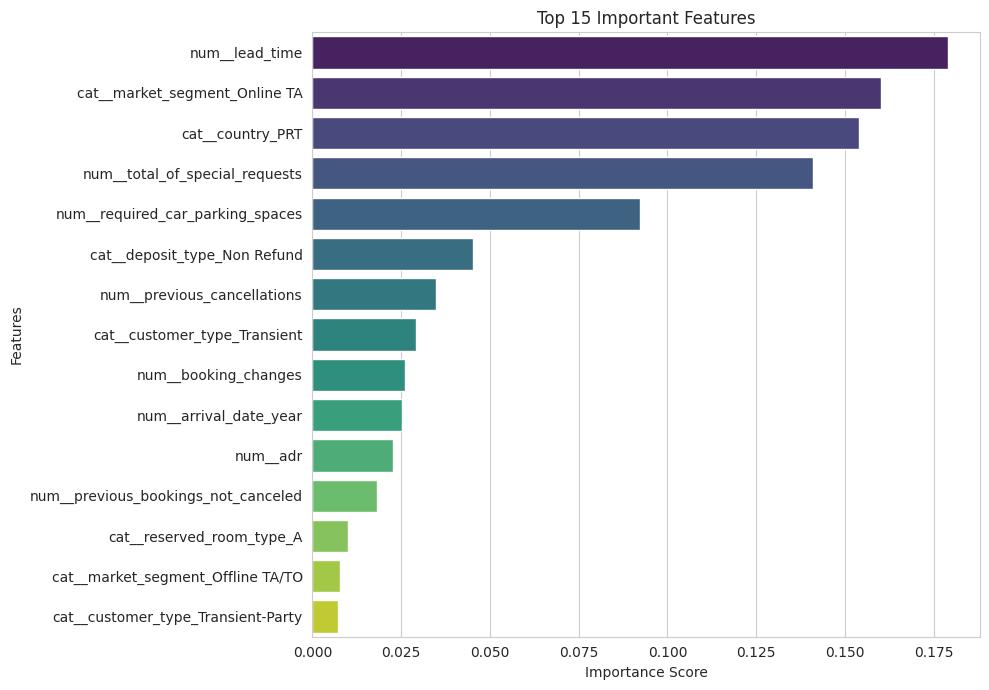

In [18]:
# STEP 13: FEATURE IMPORTANCE

feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": model.feature_importances_
})

# Select top 15 important features
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="viridis",
    legend=False
)

plt.title("Top 15 Important Features")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

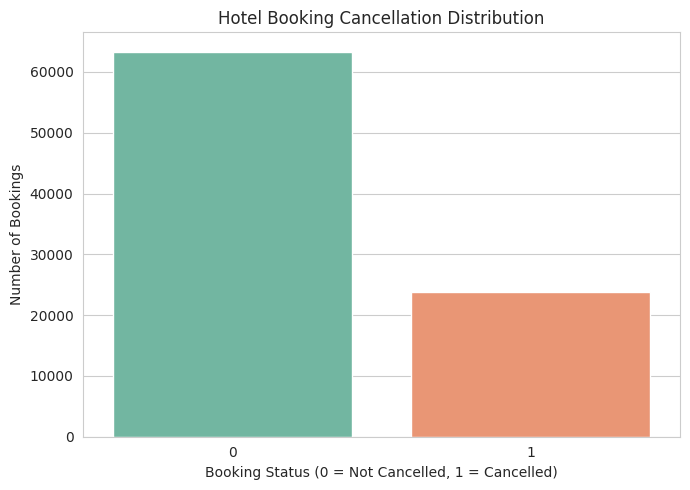

In [19]:
# STEP 14: CANCELLATION DISTRIBUTION VISUALIZATION

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="is_canceled",
    hue="is_canceled",
    palette="Set2",
    legend=False
)

plt.title("Hotel Booking Cancellation Distribution")
plt.xlabel("Booking Status (0 = Not Cancelled, 1 = Cancelled)")
plt.ylabel("Number of Bookings")

plt.tight_layout()
plt.show()

In [20]:
# STEP 15: FINAL RESULTS

results = pd.DataFrame({
    "Evaluation Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

print("FINAL MODEL PERFORMANCE")
display(results)

print("\nProject Completed Successfully!")
print("Dataset: Hotel Booking Demand")
print("Algorithm: Gradient Boosting Classifier")
print("Prediction: Hotel Booking Cancellation")

FINAL MODEL PERFORMANCE


,Evaluation Metric,Score
0,Accuracy,0.820859
1,Precision,0.732668
2,Recall,0.540404
3,F1 Score,0.622018
4,ROC-AUC,0.877871



Project Completed Successfully!
Dataset: Hotel Booking Demand
Algorithm: Gradient Boosting Classifier
Prediction: Hotel Booking Cancellation


In [26]:
# STEP 1: IMPORT RANDOM FOREST

from sklearn.ensemble import RandomForestClassifier

print("Random Forest imported successfully!")

Random Forest imported successfully!


In [27]:
# STEP 2: RANDOM FOREST MODEL TRAINING

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train_processed, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [29]:
# STEP 3: MODEL PREDICTION

rf_pred = rf_model.predict(X_test_processed)

rf_probability = rf_model.predict_proba(
    X_test_processed
)[:, 1]

print("Predictions generated successfully!")

print("\nActual Values:")
print(y_test.iloc[:10].values)

print("\nPredicted Values:")
print(rf_pred[:10])

Predictions generated successfully!

Actual Values:
[0 1 0 1 0 0 0 0 0 0]

Predicted Values:
[0 0 0 1 0 0 0 0 1 0]


In [30]:
# STEP 4: MODEL EVALUATION

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred)
rf_recall = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)
rf_roc_auc = roc_auc_score(y_test, rf_probability)

print("RANDOM FOREST PERFORMANCE")
print("-------------------------------")

print(f"Accuracy  : {rf_accuracy:.4f}")
print(f"Precision : {rf_precision:.4f}")
print(f"Recall    : {rf_recall:.4f}")
print(f"F1 Score  : {rf_f1:.4f}")
print(f"ROC-AUC   : {rf_roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

RANDOM FOREST PERFORMANCE
-------------------------------
Accuracy  : 0.8244
Precision : 0.7944
Recall    : 0.4806
F1 Score  : 0.5989
ROC-AUC   : 0.8879

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.95      0.89     12670
           1       0.79      0.48      0.60      4752

    accuracy                           0.82     17422
   macro avg       0.81      0.72      0.74     17422
weighted avg       0.82      0.82      0.81     17422



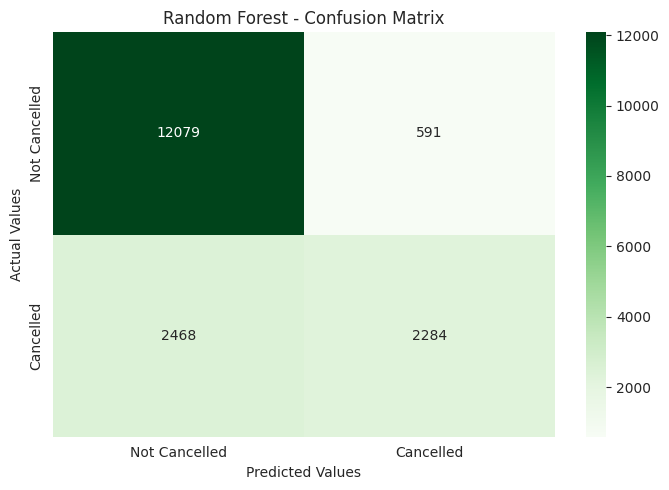

In [31]:
# STEP 5: CONFUSION MATRIX

from sklearn.metrics import confusion_matrix

rf_cm = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Not Cancelled", "Cancelled"],
    yticklabels=["Not Cancelled", "Cancelled"]
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.tight_layout()
plt.show()

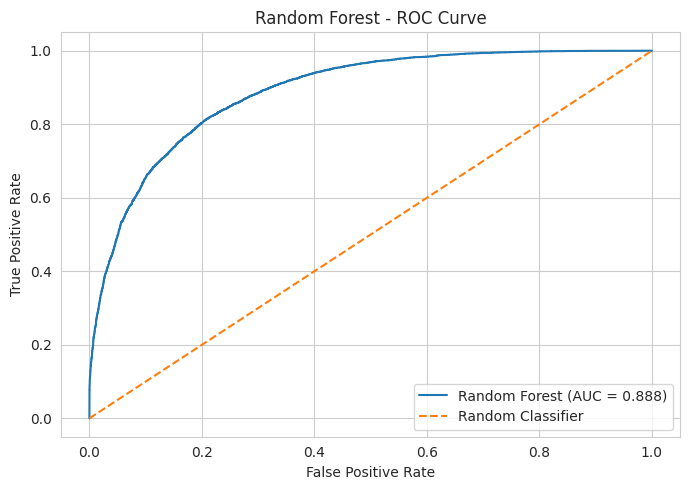

In [32]:
# STEP 6: ROC CURVE

from sklearn.metrics import roc_curve

rf_fpr, rf_tpr, rf_thresholds = roc_curve(
    y_test,
    rf_probability
)

plt.figure(figsize=(7, 5))

plt.plot(
    rf_fpr,
    rf_tpr,
    label=f"Random Forest (AUC = {rf_roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("Random Forest - ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

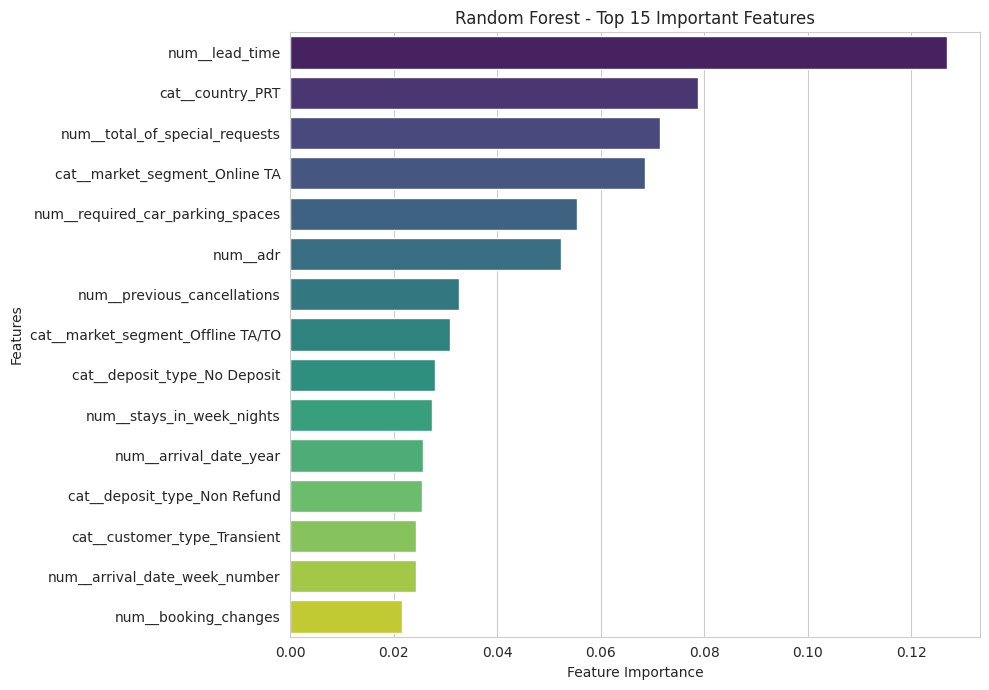

In [33]:
# STEP 7: FEATURE IMPORTANCE

feature_names = preprocessor.get_feature_names_out()

rf_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

rf_importance_df = rf_importance_df.sort_values(
    by="Importance",
    ascending=False
).head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=rf_importance_df,
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="viridis",
    legend=False
)

plt.title("Random Forest - Top 15 Important Features")
plt.xlabel("Feature Importance")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

In [34]:
# STEP 8: ALGORITHM COMPARISON

comparison = pd.DataFrame({
    "Evaluation Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],

    "Gradient Boosting": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ],

    "Random Forest": [
        rf_accuracy,
        rf_precision,
        rf_recall,
        rf_f1,
        rf_roc_auc
    ]
})

display(comparison.round(4))

,Evaluation Metric,Gradient Boosting,Random Forest
0,Accuracy,0.8209,0.8244
1,Precision,0.7327,0.7944
2,Recall,0.5404,0.4806
3,F1 Score,0.6220,0.5989
4,ROC-AUC,0.8779,0.8879


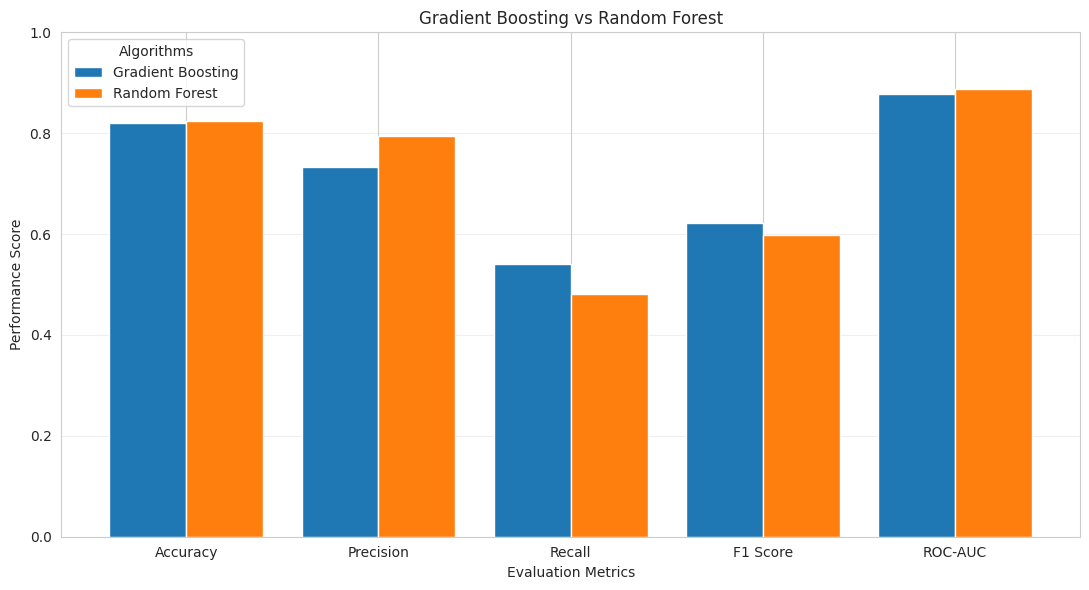

In [35]:
# STEP 9: PERFORMANCE COMPARISON GRAPH

comparison_plot = comparison.set_index(
    "Evaluation Metric"
)

comparison_plot.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.8
)

plt.title("Gradient Boosting vs Random Forest")
plt.ylabel("Performance Score")
plt.xlabel("Evaluation Metrics")

plt.xticks(rotation=0)
plt.ylim(0, 1)

plt.legend(title="Algorithms")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [36]:

# STEP: SAMPLE PREDICTIONS USING BOTH ALGORITHMS

# Create sample booking data
sample_booking = pd.DataFrame([{
    "hotel": "City Hotel",
    "lead_time": 120,
    "arrival_date_year": 2017,
    "arrival_date_month": "July",
    "arrival_date_week_number": 27,
    "arrival_date_day_of_month": 10,
    "stays_in_weekend_nights": 1,
    "stays_in_week_nights": 3,
    "adults": 2,
    "children": 0,
    "babies": 0,
    "meal": "BB",
    "country": "PRT",
    "market_segment": "Online TA",
    "distribution_channel": "TA/TO",
    "is_repeated_guest": 0,
    "previous_cancellations": 1,
    "previous_bookings_not_canceled": 0,
    "reserved_room_type": "A",
    "assigned_room_type": "A",
    "booking_changes": 0,
    "deposit_type": "No Deposit",
    "days_in_waiting_list": 0,
    "customer_type": "Transient",
    "adr": 100.0,
    "required_car_parking_spaces": 0,
    "total_of_special_requests": 2
}])

# Ensure the columns match the training data
sample_booking = sample_booking[X.columns]

# Apply the already-fitted preprocessing pipeline
sample_processed = preprocessor.transform(sample_booking)

# Gradient Boosting prediction
gb_prediction = model.predict(sample_processed)[0]
gb_probability = model.predict_proba(sample_processed)[0][1]

# Random Forest prediction
rf_prediction = rf_model.predict(sample_processed)[0]
rf_sample_probability = rf_model.predict_proba(sample_processed)[0][1]

# Display results
results = pd.DataFrame({
    "Algorithm": ["Gradient Boosting", "Random Forest"],
    "Prediction": [
        "Cancelled" if gb_prediction == 1 else "Not Cancelled",
        "Cancelled" if rf_prediction == 1 else "Not Cancelled"
    ],
    "Cancellation Probability (%)": [
        round(gb_probability * 100, 2),
        round(rf_sample_probability * 100, 2)
    ]
})

print("SAMPLE HOTEL BOOKING PREDICTIONS")
display(results)

SAMPLE HOTEL BOOKING PREDICTIONS


,Algorithm,Prediction,Cancellation Probability (%)
0,Gradient Boosting,Cancelled,91.52
1,Random Forest,Cancelled,74.49
